# ❤️ Machine Learning — Lecture 3: Logistic Regression, Feature Scaling & Classification Metrics

Welcome to Lecture 3! Pichle do lectures me hum continuous numbers (charges) predict kar rahe the (Regression). Lekin real-world AI problems me zyadatar sawal **Yes ya No** ke hote hain:
- Kya is patient ko Heart Disease hai ya nahi? ($1$ ya $0$)
- Kya ye email Spam hai ya Normal?
- Kya customer agle mahine service chhodkar jayega (Churn) ya nahi?

Is type ke problems ko hum kehte hain **Classification**! Aur iska sabse pehla aur powerful foundational algorithm hai: **Logistic Regression**.

---

### 🗺️ Lecture 3 Roadmap:
1. **Why Linear Regression Fails for Classification** — Probabilities $<0$ aur $>1$ ki problem
2. **The Sigmoid Function ($\sigma$)** — Numbers ko 0 aur 1 ke beech squash karna
3. **Decision Boundary** — 0.5 threshold ka khel
4. **Log-Loss (Binary Cross-Entropy Cost Function)** — Convex optimization
5. **Feature Scaling (`StandardScaler`)** — High-magnitude features aur Gradient Descent speed
6. **Hands-On Project on `heart.csv`**:
   - Patient Data Loading & Class Distribution inspection
   - Train-Test Split
   - Initial Logistic Regression training
   - Scaling with `StandardScaler` (Avoiding Data Leakage)
7. **Comprehensive Classification Evaluation**:
   - The Confusion Matrix (TP, FP, TN, FN) with Seaborn Heatmap
   - **Accuracy** — Kab use karein aur kab ye dhoka deta hai
   - **Precision** — "Model ke predictions kitne trustworthy hain?"
   - **Recall (Sensitivity)** — "Sach me kitne beemar logo ko model ne pakad liya?"
   - **F1-Score** — Precision aur Recall ka harmonic balance
   - `classification_report()` walkthrough


## 1. ❌ Why Linear Regression Fails for Classification

Bahut log sochte hain: "Agar target 0 aur 1 hai, to Linear Regression ki line kheech kar 0.5 se upar wale ko 1 aur neeche wale ko 0 maan lete hain! Problem solved?"

Lekin iske 2 bohot bade fatal flaws hain:

1. **Unbounded Predictions:**
   Linear line ki equation hoti hai $\hat{y} = mx + c$. Agar $x$ bohot bada ho jaye to $\hat{y} = 2.5$ ya $10.0$ aa sakta hai. Aur agar $x$ chhota ho to $\hat{y} = -1.5$ aa sakta hai!
   Lekin **Probability hamesha 0 aur 1 ke beech honi chahiye ($0 \le P \le 1$)**! Negative probability ka koi matlab nahi hota.

2. **Outlier Sensitivity (Decision Boundary Shift):**
   Agar dataset me ek bohot bada extreme data point aa jaye, to Linear Regression us point ke kareeb aane ke liye apni poori line ko tilt kar deta hai, jisse pehle se sahi classify ho rahe points bhi galat classify hone lagte hain!

Isliye hume ek aisi curve chahiye jo kabhi 0 se neeche na jaye aur 1 se upar na jaye!


## 2. 🌀 The Sigmoid Function (S-Curve)

Hume ek aisi mathematical machine chahiye jo kisi bhi number $(-\infty \text{ se } +\infty)$ ko **$0$ aur $1$ ke beech** me daba (squash) kar de.

Is magical function ka naam hai **Sigmoid (Logistic) Function**:
$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Yaha $z$ hamari linear equation hai:
$$z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b = W \cdot X + b$$

To Logistic Regression ka final prediction formula banta hai:
$$\hat{p} = P(y = 1 \mid X) = \frac{1}{1 + e^{-(W \cdot X + b)}}$$

### 💡 Properties of Sigmoid:
- Jab $z = 0 \implies \sigma(0) = \frac{1}{1 + 1} = 0.5$ (50% chance).
- Jab $z \to +\infty \implies e^{-\infty} \to 0 \implies \sigma(z) \to 1$ (100% chance).
- Jab $z \to -\infty \implies e^{\infty} \to \infty \implies \sigma(z) \to 0$ (0% chance).

---

## 3. 🎯 Decision Boundary (Thresholding)

Sigmoid se hume ek **Probability ($\hat{p}$)** milti hai (jaise $0.85$ yaani 85% chance of heart disease).
Category (0 ya 1) banane ke liye hum ek **Threshold (usually 0.5)** set karte hain:

$$\hat{y} = \begin{cases} 1 & \text{if } \hat{p} \ge 0.5 \quad (z \ge 0) \\ 0 & \text{if } \hat{p} < 0.5 \quad (z < 0) \end{cases}$$

Chalo pehle Sigmoid curve ka ek visual plot dekhte hain:


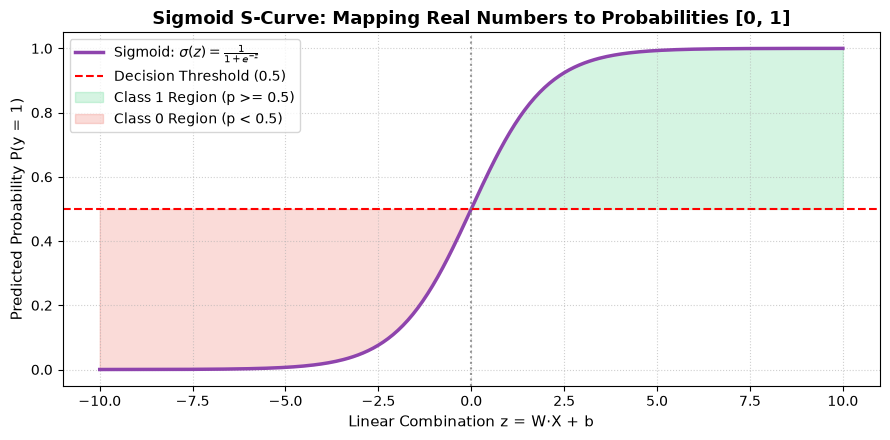

In [1]:
# Visualizing the Sigmoid Function & Decision Boundary
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-10, 10, 300)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(9, 4.5))
plt.plot(z, sigmoid, color='#8e44ad', linewidth=2.5, label=r'Sigmoid: $\sigma(z) = \frac{1}{1 + e^{-z}}$')
plt.axhline(0.5, color='red', linestyle='--', linewidth=1.5, label='Decision Threshold (0.5)')
plt.axvline(0, color='gray', linestyle=':', alpha=0.8)

# Shading regions
plt.fill_between(z, 0.5, sigmoid, where=(z >= 0), color='#2ecc71', alpha=0.2, label='Class 1 Region (p >= 0.5)')
plt.fill_between(z, sigmoid, 0.5, where=(z < 0), color='#e74c3c', alpha=0.2, label='Class 0 Region (p < 0.5)')

plt.title("Sigmoid S-Curve: Mapping Real Numbers to Probabilities [0, 1]", fontsize=13, fontweight='bold')
plt.xlabel("Linear Combination z = W·X + b", fontsize=11)
plt.ylabel("Predicted Probability P(y = 1)", fontsize=11)
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


## 4. 📉 Log-Loss (Binary Cross-Entropy Cost Function)

Classification me hum **Mean Squared Error (MSE)** kyu use nahi karte?
Kyunki Sigmoid ke sath MSE ka graph pahadi aur khaddho jaisa non-convex ban jata hai, jisme Gradient Descent galat local minimum me fas jata hai!

Isliye hum use karte hain **Binary Cross-Entropy (Log-Loss)**:
$$\text{Cost}(y, \hat{p}) = - \left[ y \log(\hat{p}) + (1 - y) \log(1 - \hat{p}) \right]$$

### 💡 Intuition (Heavy Penalty for Confident Mistakes!):
- **Case 1: Actual $y = 1$:**
  $$\text{Cost} = -\log(\hat{p})$$
  Agar model ne $\hat{p} = 0.99$ bola to cost $\approx 0$.
  Lekin agar model ne $\hat{p} = 0.01$ bola (overconfident galat prediction), to $-\log(0.01)$ bohot bada number ban jayega! Model ko heavy punishment milti hai!
- **Case 2: Actual $y = 0$:**
  $$\text{Cost} = -\log(1 - \hat{p})$$
  Agar model ne $\hat{p} = 0.01$ bola to cost $\approx 0$. Agar $\hat{p} = 0.99$ bola to huge penalty!


## 5. ⚖️ The Role of Feature Scaling (`StandardScaler`)

Hamare dataset `heart.csv` me alag-alag features ki values dekho:
- `chol` (Cholesterol): 120 se 564 tak
- `trestbps` (Resting Blood Pressure): 94 se 200 tak
- `thalach` (Max Heart Rate): 71 se 202 tak
- Jabki `sex`, `fbs`, `exang`: sirf 0 ya 1 hain!
- Aur `oldpeak`: 0.0 se 6.2 tak hai.

### ❓ Kyu zaroori hai scaling?
Agar hum scale nahi karenge, to `chol` (200-500) ke bade numbers model ke weights ko dominate kar lenge aur Gradient Descent ko slow aur un-stable bana denge!

### 📐 StandardScaler ($Z$-score Scaling - Day 20 Connection!):
$$Z = \frac{X - \mu}{\sigma}$$
Ye har feature ka Mean $\mu = 0$ aur Standard Deviation $\sigma = 1$ kar deta hai!

### ⚠️ Data Leakage Se Bachne Ka Niyam:
- Training set par: `scaler.fit_transform(X_train)` (Mean aur Std seekho aur transform karo).
- Testing set par: `scaler.transform(X_test)` (Sirf training ke Mean/Std se transform karo, test data ka distribution model ko pata nahi chalna chahiye!).


## 6. 🏥 Hands-On Project: Heart Disease Prediction (`heart.csv`)

Hamare paas heart disease ka dataset hai:
- Features: `age`, `sex`, `cp` (chest pain type), `trestbps`, `chol`, `fbs`, `restecg`, `thalach`, `exang`, `oldpeak`, `slope`, `ca`, `thal`
- **`target` (Output $y$):**
  - `1` = Patient ko Heart Disease hai
  - `0` = Patient Healthy hai (No Heart Disease)

Chalo data load karke inspect karte hain!


In [2]:
# Step 1: Data Loading & Exploration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_heart = pd.read_csv("data/heart.csv")

print("Dataset Shape:", df_heart.shape)
print("\nClass Distribution in Target (0 vs 1):")
print(df_heart["target"].value_counts())

df_heart.head()


Dataset Shape: (303, 14)

Class Distribution in Target (0 vs 1):
target
1    165
0    138
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
# Step 2: Features X aur Target y alag karna & Train-Test Split
from sklearn.model_selection import train_test_split

X = df_heart.drop("target", axis=1)
y = df_heart["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training samples: {X_train.shape[0]} (Diseased: {(y_train == 1).sum()}, Healthy: {(y_train == 0).sum()})")
print(f"Testing samples:  {X_test.shape[0]}")


Training samples: 242 (Diseased: 133, Healthy: 109)
Testing samples:  61


### 🧪 Baseline Logistic Regression (Bina Feature Scaling ke)
Pehle bina scale kiye model train karke dekhte hain:


In [4]:
# Training without Feature Scaling
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score

model_raw = LogisticRegression(max_iter=1000, random_state=42)
model_raw.fit(X_train, y_train)

y_pred_raw = model_raw.predict(X_test)

print(f"Baseline Accuracy:  {accuracy_score(y_test, y_pred_raw)*100:.2f}%")
print(f"Baseline Precision: {precision_score(y_test, y_pred_raw)*100:.2f}%")


Baseline Accuracy:  88.52%
Baseline Precision: 87.88%


### 🚀 Applying `StandardScaler` (Proper Feature Scaling)
Ab `StandardScaler` apply karte hain aur dekhte hain convergence aur performance:


In [5]:
# Applying StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Training data par fit_transform
X_train_scaled = scaler.fit_transform(X_train)

# Testing data par ONLY transform (No fit!)
X_test_scaled = scaler.transform(X_test)

# Train model on scaled data
model_scaled = LogisticRegression(max_iter=1000, random_state=42)
model_scaled.fit(X_train_scaled, y_train)

y_pred_scaled = model_scaled.predict(X_test_scaled)

print(f"Scaled Model Accuracy:  {accuracy_score(y_test, y_pred_scaled)*100:.2f}%")
print(f"Scaled Model Precision: {precision_score(y_test, y_pred_scaled)*100:.2f}%")


Scaled Model Accuracy:  85.25%
Scaled Model Precision: 87.10%


## 7. 🎯 Classification Evaluation Metrics — Beyond Just Accuracy!

Medical diagnosis me sirf **Accuracy** dekhna jaanleva ho sakta hai! Socho agar 100 me se 95 log healthy hain aur 5 ko cancer hai, agar ek model sabko आंख band karke "Healthy (0)" bol de, to uski accuracy **95%** hogi, par wo saare 5 cancer patients ko maar dega!

Isliye hume **Confusion Matrix** aur uske metrics samajhna zaroori hai.

---

### 🧩 The Confusion Matrix:
| | Predicted Negative ($0$) | Predicted Positive ($1$) |
| :--- | :--- | :--- |
| **Actual Negative ($0$)** | **TN (True Negative):** Healthy tha, Healthy bola ✅ | **FP (False Positive):** Healthy tha, Beemar bol diya (False Alarm) ⚠️ |
| **Actual Positive ($1$)** | **FN (False Negative):** Beemar tha, Healthy bol diya (**DANGEROUS!**) ❌ | **TP (True Positive):** Beemar tha, Beemar pakda ✅ |

---

### 📐 Key Metrics Explained:
1. **Accuracy:** Overall kitne predictions sahi the:
   $$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

2. **Precision (Quality of Positive Predictions):**
   $$\text{Precision} = \frac{TP}{TP + FP}$$
   - *"Jab model ne bola ki patient beemar hai, to usme se sach me kitne percent beemar the?"*
   - Use case: Spam detection (Hum nahi chahte ki koi important mail spam me chali jaye).

3. **Recall / Sensitivity (Quantity of Positives Caught):**
   $$\text{Recall} = \frac{TP}{TP + FN}$$
   - *"Asal me jitne beemar log the, unme se model ne kitne percent ko pakad liya?"*
   - **Medical domain me Recall sabse critical hota hai!** Hum False Negative (FN) bardasht nahi kar sakte!

4. **F1-Score (Harmonic Mean):**
   $$F_1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$
   - Precision aur Recall ka balanced score.

Chalo Confusion Matrix ko plot karte hain aur saare metrics print karte hain:


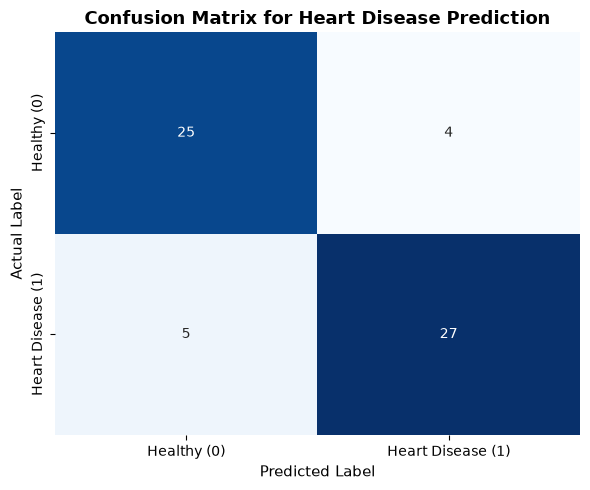

True Negatives  (TN): 25
False Positives (FP): 4
False Negatives (FN): 5 (Missed Patients)
True Positives  (TP): 27 (Correctly Diagnosed)


In [6]:
# Visualizing Confusion Matrix with Seaborn Heatmap
from sklearn.metrics import confusion_matrix, classification_report, recall_score, f1_score

cm = confusion_matrix(y_test, y_pred_scaled)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Healthy (0)', 'Heart Disease (1)'],
            yticklabels=['Healthy (0)', 'Heart Disease (1)'])

plt.title("Confusion Matrix for Heart Disease Prediction", fontsize=13, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("Actual Label", fontsize=11)
plt.tight_layout()
plt.show()

# Extracting TP, FP, TN, FN
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn} (Missed Patients)")
print(f"True Positives  (TP): {tp} (Correctly Diagnosed)")


In [7]:
# Detailed Classification Report
print("--- Detailed Evaluation Metrics ---")
print(f"Accuracy Score:  {accuracy_score(y_test, y_pred_scaled):.4f} ({accuracy_score(y_test, y_pred_scaled)*100:.2f}%)")
print(f"Precision Score: {precision_score(y_test, y_pred_scaled):.4f} ({precision_score(y_test, y_pred_scaled)*100:.2f}%)")
print(f"Recall Score:    {recall_score(y_test, y_pred_scaled):.4f} ({recall_score(y_test, y_pred_scaled)*100:.2f}%)")
print(f"F1 Score:        {f1_score(y_test, y_pred_scaled):.4f} ({f1_score(y_test, y_pred_scaled)*100:.2f}%)")

print("\n--- Full Scikit-Learn Classification Report ---")
print(classification_report(y_test, y_pred_scaled, target_names=['Healthy', 'Heart Disease']))


--- Detailed Evaluation Metrics ---
Accuracy Score:  0.8525 (85.25%)
Precision Score: 0.8710 (87.10%)
Recall Score:    0.8438 (84.38%)
F1 Score:        0.8571 (85.71%)

--- Full Scikit-Learn Classification Report ---
               precision    recall  f1-score   support

      Healthy       0.83      0.86      0.85        29
Heart Disease       0.87      0.84      0.86        32

     accuracy                           0.85        61
    macro avg       0.85      0.85      0.85        61
 weighted avg       0.85      0.85      0.85        61



---

## 🎯 Lecture 3 Summary & Revision Checklist

Ab aap Classification aur Logistic Regression ke complete concepts ko master kar chuke hain:
- [x] **Linear vs Logistic:** Linear regression classification me probabilities boundary cross kar leti hai, isliye Logistic Regression use hota hai.
- [x] **Sigmoid Function:** $\sigma(z) = \frac{1}{1 + e^{-z}}$ outputs ko $0$ aur $1$ ke beech squash karta hai.
- [x] **Cost Function:** Log-Loss (Binary Cross-Entropy) overconfident galat predictions par infinite penalty deta hai.
- [x] **StandardScaler:** $Z = (X - \mu)/\sigma$ Gradient Descent ko fast aur stable banata hai.
- [x] **Data Leakage Rule:** Hamesha `fit_transform` on train, aur ONLY `transform` on test set!
- [x] **Evaluation Metrics:**
  - Accuracy: Overall correctness.
  - Precision: Predicted Positives ki reliability.
  - Recall: Actual Positives ko pakadne ki shamta (Healthcare me sabse critical!).
  - F1-Score: Precision aur Recall ka harmonic balance.

---

### 🏆 CONGRATULATIONS! Machine Learning Foundations (Day 23 & 24) Mastered!
Aapne **Simple Linear Regression, Multiple Linear Regression, Feature Engineering, Dummy Variable Trap, Lasso/Ridge Regularization, Hyperparameter Tuning (LassoCV), Logistic Regression, Feature Scaling, aur Confusion Matrix & Classification Metrics** ko complete hands-on practical implementation ke sath master kar liya hai!
